In [1]:
from pathlib import Path

import torch
import numpy as np
import ot

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

FEATURE_FILE = (
    PROJECT_ROOT
    / "experiments"
    / "features"
    / "office31_amazon_webcam_features.pt"
)

OUTPUT_DIR = PROJECT_ROOT / "experiments" / "features" / "adapted"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

data = torch.load(
    FEATURE_FILE,
    map_location="cpu",
    weights_only=False
)

Xs_train = data["Xs_train"].numpy()
Xt_adapt = data["Xt_adapt"].numpy()
ys_train = data["ys_train"].numpy()

CLASSES = data["classes"]

print("Source features:", Xs_train.shape)
print("Target adaptation features:", Xt_adapt.shape)
print("Source labels:", ys_train.shape)
print("Number of classes:", len(CLASSES))
print("POT version:", ot.__version__)

Source features: (2253, 512)
Target adaptation features: (397, 512)
Source labels: (2253,)
Number of classes: 31
POT version: 0.9.7.post1


In [2]:
from sklearn.metrics import pairwise_distances

cost_matrix = pairwise_distances(
    Xs_train,
    Xt_adapt,
    metric="sqeuclidean"
)

print("Cost matrix shape:", cost_matrix.shape)
print("Minimum cost:", cost_matrix.min())
print("Maximum cost:", cost_matrix.max())
print("Mean cost:", cost_matrix.mean())
print("All finite:", np.isfinite(cost_matrix).all())

Cost matrix shape: (2253, 397)
Minimum cost: 111.3878422844711
Maximum cost: 1718.0516943901016
Mean cost: 656.408906629065
All finite: True


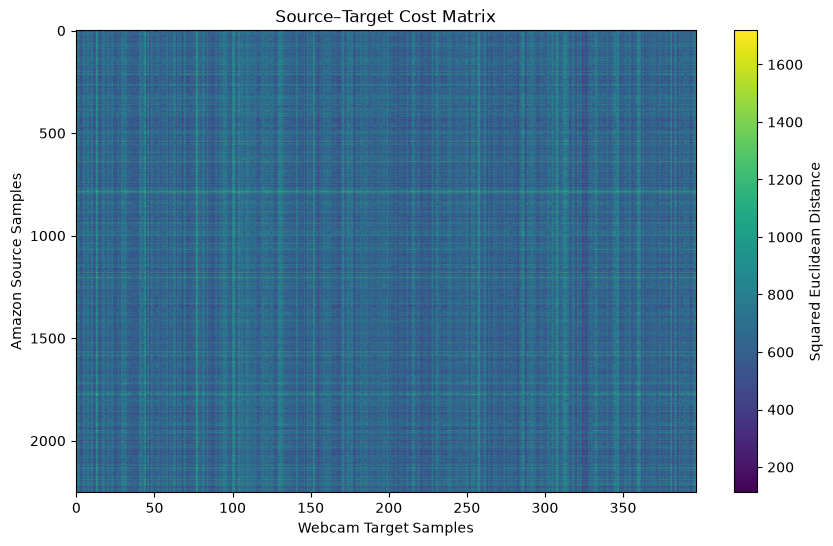

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.imshow(
    cost_matrix,
    aspect="auto",
    cmap="viridis"
)

plt.colorbar(label="Squared Euclidean Distance")
plt.xlabel("Webcam Target Samples")
plt.ylabel("Amazon Source Samples")
plt.title("Source–Target Cost Matrix")

plt.show()

### First experiment — EMD Transport

In [4]:
emd = ot.da.EMDTransport(
    metric="sqeuclidean"
)

emd.fit(
    Xs=Xs_train,
    Xt=Xt_adapt
)

print("EMD fitting completed!")
print("Transport plan shape:", emd.coupling_.shape)

EMD fitting completed!
Transport plan shape: (2253, 397)


In [5]:
transport_plan = emd.coupling_

print("Transport plan shape:", transport_plan.shape)
print("Total transported mass:", transport_plan.sum())

print("Minimum:", transport_plan.min())
print("Maximum:", transport_plan.max())

print(
    "Maximum row marginal error:",
    np.abs(
        transport_plan.sum(axis=1) - 1 / len(Xs_train)
    ).max()
)

print(
    "Maximum column marginal error:",
    np.abs(
        transport_plan.sum(axis=0) - 1 / len(Xt_adapt)
    ).max()
)

Transport plan shape: (2253, 397)
Total transported mass: 1.0
Minimum: 0.0
Maximum: 0.00044385265
Maximum row marginal error: 2.910383e-11
Maximum column marginal error: 4.656613e-10


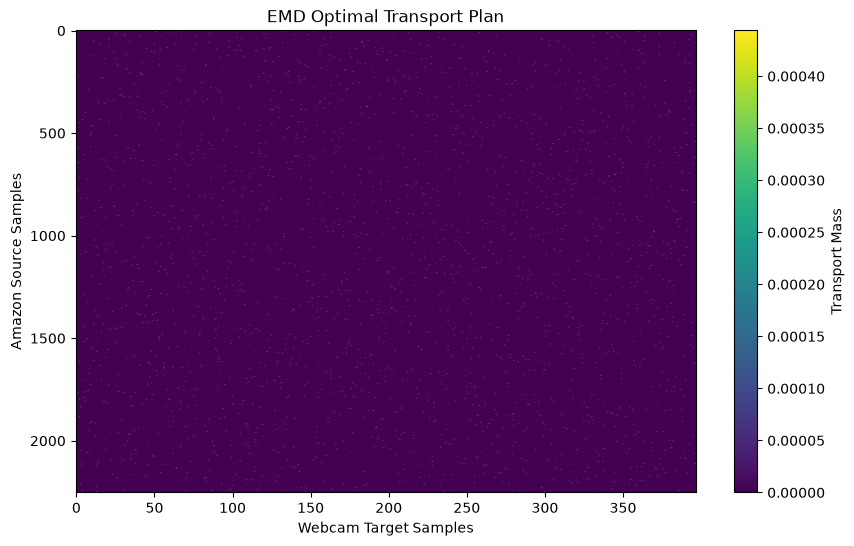

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.imshow(
    transport_plan,
    aspect="auto",
    cmap="viridis"
)

plt.colorbar(label="Transport Mass")
plt.xlabel("Webcam Target Samples")
plt.ylabel("Amazon Source Samples")
plt.title("EMD Optimal Transport Plan")

plt.show()

In [7]:
Xs_train_emd = emd.transform(Xs=Xs_train)

print("Original source features:", Xs_train.shape)
print("EMD adapted features:", Xs_train_emd.shape)
print("All finite:", np.isfinite(Xs_train_emd).all())

Original source features: (2253, 512)
EMD adapted features: (2253, 512)
All finite: True


In [8]:
emd_file = OUTPUT_DIR / "emd.pt"

torch.save(
    {
        "Xs_train_adapted": torch.tensor(
            Xs_train_emd, dtype=torch.float32
        ),
        "ys_train": torch.tensor(
            ys_train, dtype=torch.long
        ),
        "transport_plan": torch.tensor(
            transport_plan, dtype=torch.float32
        ),
        "method": "EMD",
        "source_domain": "amazon",
        "target_domain": "webcam",
        "seed": 42
    },
    emd_file
)

print("Saved:", emd_file)
print("File size (MB):", round(emd_file.stat().st_size / (1024**2), 2))

Saved: d:\DUK- Research Collab\Sanjay PhD\cnn-domain-adaptation-optimal-transport\experiments\features\adapted\emd.pt
File size (MB): 7.83


### Experiment 2 — Sinkhorn Transport

In [9]:
reg_e = 0.05 * cost_matrix.mean()

sinkhorn = ot.da.SinkhornTransport(
    metric="sqeuclidean",
    reg_e=reg_e,
    max_iter=1000,
    tol=1e-9,
    verbose=True
)

sinkhorn.fit(
    Xs=Xs_train,
    Xt=Xt_adapt
)

print("Sinkhorn fitting completed!")
print("Regularization parameter:", reg_e)
print("Transport plan shape:", sinkhorn.coupling_.shape)

It.  |Err         
-------------------
    0|2.416552e-02|
   10|7.245249e-04|
   20|9.513159e-05|
   30|3.396617e-05|
   40|1.520459e-05|
   50|6.960976e-06|
   60|3.195575e-06|
   70|1.467492e-06|
   80|6.739285e-07|
   90|3.095013e-07|
  100|1.421634e-07|
  110|6.535726e-08|
  120|3.017190e-08|
  130|1.419588e-08|
  140|7.214316e-09|
  150|4.530410e-09|
  160|3.725224e-09|
  170|3.532068e-09|
  180|3.489971e-09|
  190|3.481028e-09|
It.  |Err         
-------------------
  200|3.479139e-09|
  210|3.478741e-09|
  220|3.478657e-09|
  230|3.478639e-09|
  240|3.478635e-09|
  250|3.478635e-09|
  260|3.478634e-09|
  270|3.478634e-09|
  280|3.478634e-09|
  290|3.478634e-09|
  300|3.478634e-09|
  310|3.478634e-09|
  320|3.478634e-09|
  330|3.478634e-09|
  340|3.478634e-09|
  350|3.478634e-09|
  360|3.478634e-09|
  370|3.478634e-09|
  380|3.478634e-09|
  390|3.478634e-09|
It.  |Err         
-------------------
  400|3.478634e-09|
  410|3.478634e-09|
  420|3.478634e-09|
  430|3.478634e-09|
  4

d:\DUK- Research Collab\Sanjay PhD\cnn-domain-adaptation-optimal-transport\.venv\Lib\site-packages\ot\bregman\_sinkhorn.py:902: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


In [10]:
sinkhorn_plan = sinkhorn.coupling_

print("Total transported mass:", sinkhorn_plan.sum())
print("Minimum mass:", sinkhorn_plan.min())
print("Maximum mass:", sinkhorn_plan.max())

print(
    "Maximum row marginal error:",
    np.abs(
        sinkhorn_plan.sum(axis=1) - 1 / len(Xs_train)
    ).max()
)

print(
    "Maximum column marginal error:",
    np.abs(
        sinkhorn_plan.sum(axis=0) - 1 / len(Xt_adapt)
    ).max()
)

print(
    "Non-zero transport entries (%):",
    100 * np.count_nonzero(sinkhorn_plan) / sinkhorn_plan.size
)

Total transported mass: 1.0000000304285828
Minimum mass: 3.6095457868307157e-19
Maximum mass: 0.00042615878569222053
Maximum row marginal error: 1.350580752920369e-11
Maximum column marginal error: 7.66463190658706e-11
Non-zero transport entries (%): 100.0


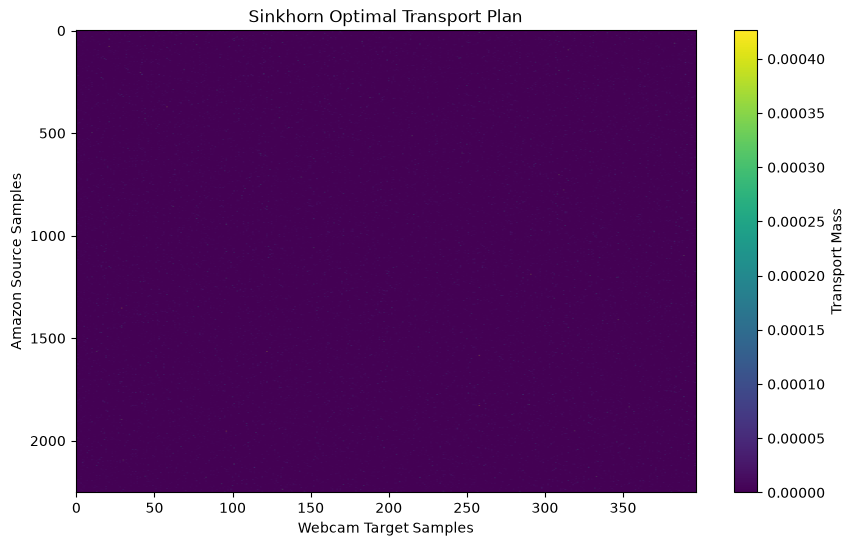

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.imshow(
    sinkhorn_plan,
    aspect="auto",
    cmap="viridis"
)

plt.colorbar(label="Transport Mass")
plt.xlabel("Webcam Target Samples")
plt.ylabel("Amazon Source Samples")
plt.title("Sinkhorn Optimal Transport Plan")

plt.show()

In [12]:
Xs_train_sinkhorn = sinkhorn.transform(Xs=Xs_train)

print("Original features:", Xs_train.shape)
print("Adapted features:", Xs_train_sinkhorn.shape)
print("All finite:", np.isfinite(Xs_train_sinkhorn).all())

Original features: (2253, 512)
Adapted features: (2253, 512)
All finite: True


In [13]:
sinkhorn_file = OUTPUT_DIR / "sinkhorn.pt"

torch.save(
    {
        "Xs_train_adapted": torch.tensor(
            Xs_train_sinkhorn, dtype=torch.float32
        ),
        "ys_train": torch.tensor(
            ys_train, dtype=torch.long
        ),
        "transport_plan": torch.tensor(
            sinkhorn_plan, dtype=torch.float32
        ),
        "method": "Sinkhorn",
        "reg_e": float(reg_e),
        "max_iter": 1000,
        "tol": 1e-9,
        "source_domain": "amazon",
        "target_domain": "webcam",
        "seed": 42
    },
    sinkhorn_file
)

print("Saved:", sinkhorn_file)
print("File size (MB):", round(sinkhorn_file.stat().st_size / (1024**2), 2))

Saved: d:\DUK- Research Collab\Sanjay PhD\cnn-domain-adaptation-optimal-transport\experiments\features\adapted\sinkhorn.pt
File size (MB): 7.83


### Experiment 3 — Sinkhorn LpL1 Transport

In [14]:
reg_e = 0.05 * cost_matrix.mean()

sinkhorn_lpl1 = ot.da.SinkhornLpl1Transport(
    reg_e=reg_e,
    reg_cl=1.0,
    max_iter=10,
    max_inner_iter=200,
    tol=1e-8,
    verbose=True
)

In [15]:
sinkhorn_lpl1.fit(
    Xs=Xs_train,
    ys=ys_train,
    Xt=Xt_adapt
)

print("Sinkhorn LpL1 fitting completed!")
print("Transport plan shape:", sinkhorn_lpl1.coupling_.shape)

Sinkhorn LpL1 fitting completed!
Transport plan shape: (2253, 397)


In [16]:
lpl1_plan = sinkhorn_lpl1.coupling_

print("Total transported mass:", lpl1_plan.sum())
print("Minimum mass:", lpl1_plan.min())
print("Maximum mass:", lpl1_plan.max())

print(
    "Maximum row marginal error:",
    np.abs(
        lpl1_plan.sum(axis=1) - 1 / len(Xs_train)
    ).max()
)

print(
    "Maximum column marginal error:",
    np.abs(
        lpl1_plan.sum(axis=0) - 1 / len(Xt_adapt)
    ).max()
)

Total transported mass: 1.0
Minimum mass: 2.806421680924016e-19
Maximum mass: 0.0004269513646029024
Maximum row marginal error: 4.336808689942018e-19
Maximum column marginal error: 1.5593233427570186e-09


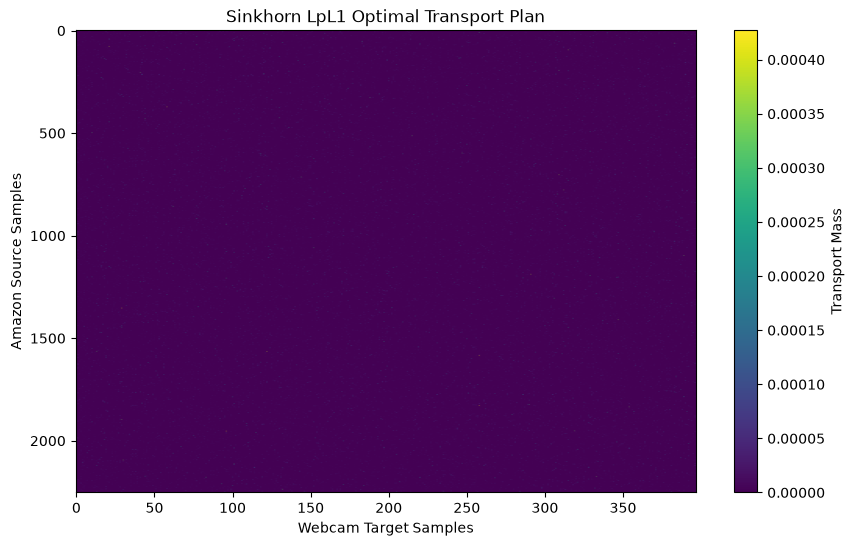

In [17]:
plt.figure(figsize=(10, 6))

plt.imshow(
    lpl1_plan,
    aspect="auto",
    cmap="viridis"
)

plt.colorbar(label="Transport Mass")
plt.xlabel("Webcam Target Samples")
plt.ylabel("Amazon Source Samples")
plt.title("Sinkhorn LpL1 Optimal Transport Plan")

plt.show()

In [18]:
Xs_train_lpl1 = sinkhorn_lpl1.transform(Xs=Xs_train)

print("Original features:", Xs_train.shape)
print("Adapted features:", Xs_train_lpl1.shape)
print("All finite:", np.isfinite(Xs_train_lpl1).all())

Original features: (2253, 512)
Adapted features: (2253, 512)
All finite: True


In [19]:
lpl1_file = OUTPUT_DIR / "sinkhorn_lpl1.pt"

torch.save(
    {
        "Xs_train_adapted": torch.tensor(
            Xs_train_lpl1, dtype=torch.float32
        ),
        "ys_train": torch.tensor(
            ys_train, dtype=torch.long
        ),
        "transport_plan": torch.tensor(
            lpl1_plan, dtype=torch.float32
        ),
        "method": "SinkhornLpl1",
        "reg_e": float(reg_e),
        "reg_cl": 1.0,
        "max_iter": 10,
        "max_inner_iter": 200,
        "tol": 1e-8,
        "source_domain": "amazon",
        "target_domain": "webcam",
        "seed": 42
    },
    lpl1_file
)

print("Saved:", lpl1_file)
print("File size (MB):", round(lpl1_file.stat().st_size / (1024**2), 2))

Saved: d:\DUK- Research Collab\Sanjay PhD\cnn-domain-adaptation-optimal-transport\experiments\features\adapted\sinkhorn_lpl1.pt
File size (MB): 7.83


### Experiment 4 — Sinkhorn L1L2 Transport

In [20]:
sinkhorn_l1l2 = ot.da.SinkhornL1l2Transport(
    reg_e=reg_e,
    reg_cl=2.0,
    max_iter=20,
    max_inner_iter=200,
    tol=1e-8,
    verbose=True
)

In [21]:
sinkhorn_l1l2.fit(
    Xs=Xs_train,
    ys=ys_train,
    Xt=Xt_adapt
)

print("Sinkhorn L1L2 fitting completed!")
print("Transport plan shape:", sinkhorn_l1l2.coupling_.shape)

It.  |Loss        |Relative loss|Absolute loss
------------------------------------------------
    0|6.566427e+02|0.000000e+00|0.000000e+00


d:\DUK- Research Collab\Sanjay PhD\cnn-domain-adaptation-optimal-transport\.venv\Lib\site-packages\ot\bregman\_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


    1|4.294596e+02|5.289976e-01|2.271831e+02
    2|4.275341e+02|4.503826e-03|1.925539e+00
    3|4.275128e+02|4.985178e-05|2.131227e-02
    4|4.275126e+02|4.612241e-07|1.971791e-04
    5|4.275126e+02|5.149636e-09|2.201534e-06
Sinkhorn L1L2 fitting completed!
Transport plan shape: (2253, 397)


In [22]:
l1l2_plan = sinkhorn_l1l2.coupling_

print("Total transported mass:", l1l2_plan.sum())
print("Minimum mass:", l1l2_plan.min())
print("Maximum mass:", l1l2_plan.max())

print(
    "Maximum row marginal error:",
    np.abs(
        l1l2_plan.sum(axis=1) - 1 / len(Xs_train)
    ).max()
)

print(
    "Maximum column marginal error:",
    np.abs(
        l1l2_plan.sum(axis=0) - 1 / len(Xt_adapt)
    ).max()
)

print(
    "Non-zero transport entries (%):",
    100 * np.count_nonzero(l1l2_plan) / l1l2_plan.size
)

Total transported mass: 1.0
Minimum mass: 1.1217204194896689e-16
Maximum mass: 0.00042555396732329943
Maximum row marginal error: 3.2526065174565133e-19
Maximum column marginal error: 1.933423733613271e-11
Non-zero transport entries (%): 100.0


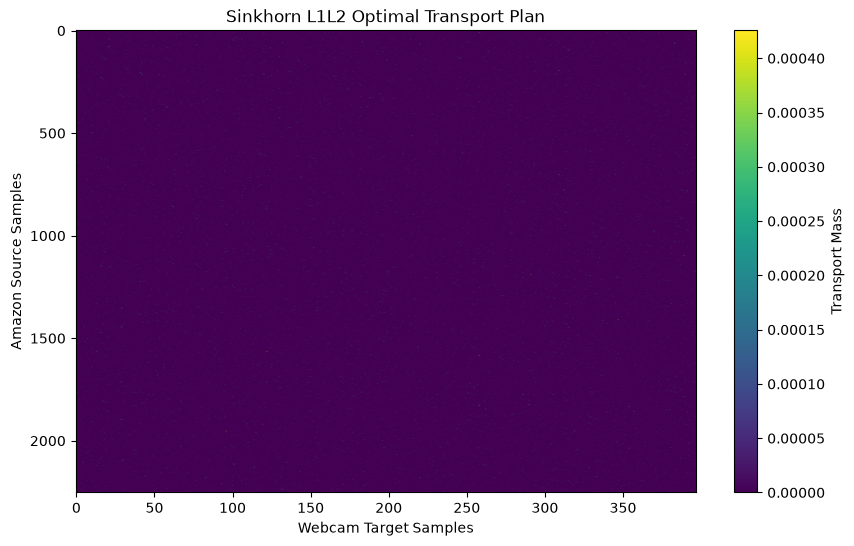

In [23]:
plt.figure(figsize=(10, 6))

plt.imshow(
    l1l2_plan,
    aspect="auto",
    cmap="viridis"
)

plt.colorbar(label="Transport Mass")
plt.xlabel("Webcam Target Samples")
plt.ylabel("Amazon Source Samples")
plt.title("Sinkhorn L1L2 Optimal Transport Plan")

plt.show()

In [24]:
Xs_train_l1l2 = sinkhorn_l1l2.transform(Xs=Xs_train)

print("Original features:", Xs_train.shape)
print("Adapted features:", Xs_train_l1l2.shape)
print("All finite:", np.isfinite(Xs_train_l1l2).all())

Original features: (2253, 512)
Adapted features: (2253, 512)
All finite: True


In [25]:
l1l2_file = OUTPUT_DIR / "sinkhorn_l1l2.pt"

torch.save(
    {
        "Xs_train_adapted": torch.tensor(
            Xs_train_l1l2, dtype=torch.float32
        ),
        "ys_train": torch.tensor(
            ys_train, dtype=torch.long
        ),
        "transport_plan": torch.tensor(
            l1l2_plan, dtype=torch.float32
        ),
        "method": "SinkhornL1L2",
        "reg_e": float(reg_e),
        "reg_cl": 2.0,
        "max_iter": 20,
        "max_inner_iter": 200,
        "tol": 1e-8,
        "source_domain": "amazon",
        "target_domain": "webcam",
        "seed": 42
    },
    l1l2_file
)

print("Saved:", l1l2_file)
print("File size (MB):", round(l1l2_file.stat().st_size / (1024**2), 2))

Saved: d:\DUK- Research Collab\Sanjay PhD\cnn-domain-adaptation-optimal-transport\experiments\features\adapted\sinkhorn_l1l2.pt
File size (MB): 7.83


In [26]:
for file in sorted(OUTPUT_DIR.glob("*.pt")):
    result = torch.load(file, map_location="cpu", weights_only=False)

    print(
        file.name,
        "| Features:", tuple(result["Xs_train_adapted"].shape),
        "| Labels:", tuple(result["ys_train"].shape)
    )

emd.pt | Features: (2253, 512) | Labels: (2253,)
sinkhorn.pt | Features: (2253, 512) | Labels: (2253,)
sinkhorn_l1l2.pt | Features: (2253, 512) | Labels: (2253,)
sinkhorn_lpl1.pt | Features: (2253, 512) | Labels: (2253,)
